>### Load modules

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

print("NumPy Version :{}".format(np.__version__))
print("TensorFlow Version :{}".format(tf.__version__))
print("Matplotlib Version :{}".format(plt.matplotlib.__version__))
print("Pandas Version :{}".format(pd.__version__))

NumPy Version :2.1.3
TensorFlow Version :2.20.0
Matplotlib Version :3.10.0
Pandas Version :2.2.3


In [ ]:
# 1. x_input, labels 만들기
x_input = np.array([[0,0], [0,1], [1,0], [1,1]], dtype= np.float32) #gate input
# labels = np.array([0, 0, 0, 1], dtype= np.float32) #AND gate
# labels = np.array([1, 1, 1, 0], dtype= np.float32) #NAND gate
# labels = np.array([0, 1, 1, 1], dtype= np.float32) #OR gate
# labels = np.array([1, 1, 1, 0], dtype= np.float32) #NOR gate
labels = np.array([0, 1, 1, 0], dtype= np.float32) #XOR gate
x_input, labels

(array([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]], dtype=float32),
 array([0., 1., 1., 0.], dtype=float32))

In [ ]:
# 2. Keras Model 정의, Model compile, Model summary
model = tf.keras.models.Sequential([
  tf.keras.Input(shape=(2, )),
  tf.keras.layers.Dense(2, activation='sigmoid'), #XOR gate
  tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.1), loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 3. Model Fit

In [ ]:
%%time
history = model.fit(x_input, labels, epochs=20000, verbose=2)

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
Epoch 17502/20000
1/1 - 0s - 43ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17503/20000
1/1 - 0s - 43ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17504/20000
1/1 - 0s - 47ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17505/20000
1/1 - 0s - 43ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17506/20000
1/1 - 0s - 44ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17507/20000
1/1 - 0s - 43ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17508/20000
1/1 - 0s - 53ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17509/20000
1/1 - 0s - 60ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17510/20000
1/1 - 0s - 47ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17511/20000
1/1 - 0s - 42ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17512/20000
1/1 - 0s - 50ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17513/20000
1/1 - 0s - 44ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17514/20000
1/1 - 0s - 49ms/step - accuracy: 1.0000 - loss: 0.0064
Epoch 17515/200

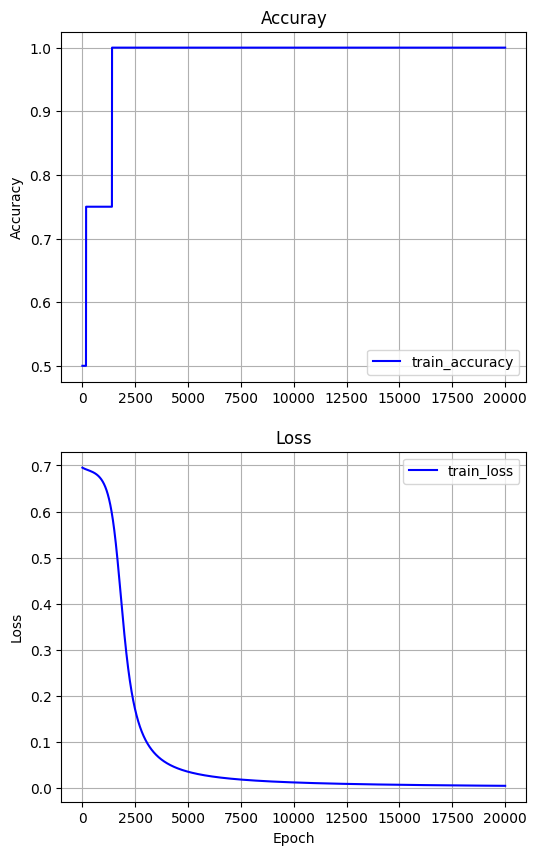

In [ ]:
# 4. accuray, loss 그래프 출력
loss = history.history['loss']
epochs = range(1, len(loss)+1)

plt.figure(figsize=(6, 10))
plt.subplot(2, 1, 1)
plt.title('Accuray')
plt.plot(epochs, history.history['accuracy'], 'b', label='train_accuracy')
plt.grid(True)
plt.ylabel('Accuracy')
plt.legend(loc='best')

plt.subplot(2, 1, 2)
plt.title('Loss')
plt.plot(epochs, history.history['loss'], 'b', label='train_loss')
plt.grid(True)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='best')
plt.show()

In [ ]:
# 5. parameter(W,B) 출력
w=model.get_weights()
print(w)

[array([[ 6.9353695,  6.359796 ],
       [-6.710481 , -6.6114345]], dtype=float32), array([ 3.3608837, -3.3845832], dtype=float32), array([[-11.336071],
       [ 11.915558]], dtype=float32), array([5.322976], dtype=float32)]


In [ ]:
# 6. Predict (x_input 사용)
H_x = model.predict(x_input)
for x,h,l in zip(x_input, H_x, labels):
  print("x:{}, h:{}, l:{}".format(x,h,l))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
x:[0. 0.], h:[0.00526039], l:0.0
x:[0. 1.], h:[0.9928901], l:1.0
x:[1. 0.], h:[0.9951516], l:1.0
x:[1. 1.], h:[0.00448978], l:0.0


Decesion boundary

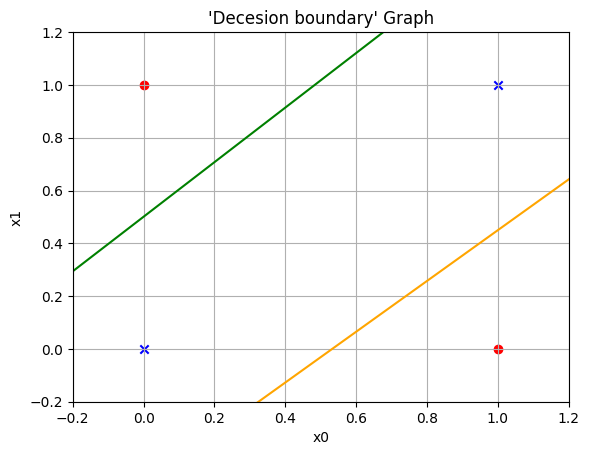

In [ ]:
# 7. 구분선 그리기
x_decision = np.linspace(-0.2, 1.2, 1000)

plt.title("'Decesion boundary' Graph")
plt.xlabel("x0")
plt.ylabel("x1")


W = w[0]
B = w[1]
y_decision1 = -(W[0][0] * x_decision + B[0])/W[1][0]
y_decision2 = -(W[0][1] * x_decision + B[1])/W[1][1]

#   label의 값에 따라서 blue 또는 red 점 찍기
for i in range(labels.shape[0]):
    if(labels[i] == 0):
        plt.scatter(x_input[i][0], x_input[i][1], color='blue', marker="x")
    else:
        plt.scatter(x_input[i][0], x_input[i][1], color='red', marker="o")

plt.plot(x_decision, y_decision1, color='green')
plt.plot(x_decision, y_decision2, color='orange')
plt.xlim((-0.2, 1.2))
plt.ylim((-0.2, 1.2))

plt.grid(True)
plt.show()